# 06 · Ocupación de urgencias y piso

Calcula la ocupación hora a hora de urgencias y del piso entre el 1 de enero de 2023 y la fecha de corte del análisis, y la relaciona con el tiempo de permanencia en urgencias.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, estilo
from src import ocupacion as oc
from src.db import consultar
from src.graficos import (
    COLORES_GRUPO,
    activar_formato_tablas,
    aplicar_estilo,
    formato_eje_fechas,
    guardar_figura,
    heatmap_hora_dia,
    leyenda_fuera,
    linea_umbral,
    titulo_hallazgo,
)
from src.privacidad import suprimir_pequenos, tabla_segura
from src.tablas import mostrar_tabla, tabla_medidas

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

## Datos

Intervalos de urgencias desde el dataset final de episodios (llegada → inicio del piso o fin de urgencias) e intervalos del piso desde la extracción `06_estancias_piso`, unidos por paciente para no contar dos veces la misma estancia. Los censos se calculan desde el 1 de enero de 2023; enero de 2023 es periodo de calentamiento y los análisis usan solo las horas y los episodios desde el 1 de febrero de 2023.

In [2]:
ruta_episodios = config.DATA_INTERIM / 'episodios_final.parquet'
if not ruta_episodios.exists():
    tabla_medidas({'archivo': 'data/interim/episodios_final.parquet', 'aviso': 'El archivo no existe.',
                   'qué hacer': 'Corre los notebooks 03 y 05 para crear el dataset final.'}, 'Dataset no disponible')
    raise SystemExit('Dataset no disponible: la celda se detiene.')

episodios = pd.read_parquet(ruta_episodios)
DESDE, HASTA = config.FECHA_INICIO_ANALISIS, config.FECHA_CORTE_ANALISIS
G1, G2, G3 = config.GRUPOS
GRUPOS_CENSO = ('total', 'adultos', 'pediatria')
NOMBRE_EDAD = {'total': 'Total', 'adultos': 'Adultos', 'pediatria': 'Pediatría'}
NOMBRE_AREA = {'urgencias_todos': 'Urgencias (todos)', 'urgencias_atencion': 'Urgencias con atención', 'piso': 'Piso'}
FAMILIA_AREA = {'urgencias_todos': 'urgencias', 'urgencias_atencion': 'urgencias', 'piso': 'hospitalizacion'}
COLOR_AREA = {'urgencias_todos': estilo.RAMPA_AZUL[5], 'urgencias_atencion': estilo.AZUL, 'piso': estilo.CIRUELA}
COLOR_CLARO_AREA = {'urgencias_todos': estilo.RAMPA_AZUL[2], 'urgencias_atencion': estilo.RAMPA_AZUL[2],
                    'piso': estilo.RAMPA_CIRUELA[2]}
NOMBRE_CAPACIDAD = {'observacion': 'observación', 'piso': 'piso', 'piso_y_especiales': 'piso y cuidados especiales'}
CAPACIDAD = oc.capacidades_actuales()
AREAS_MEDIDAS = ('urgencias_atencion', 'piso')
USAR_CAPACIDAD = {'urgencias_todos': True, 'urgencias_atencion': True, 'piso': config.USAR_CAPACIDAD_PISO}

intervalos = {
    'urgencias_todos': oc.intervalos_urgencias(episodios),
    'urgencias_atencion': oc.intervalos_urgencias(episodios, con_atencion=True),
}

In [3]:
estancias = oc.preparar_estancias_piso(consultar('06_estancias_piso'), fin_si_falta=HASTA)
piso = oc.fusionar_intervalos(estancias[['person_id', 'inicio', 'fin', 'edad', 'sin_fin', 'fin_fraccion_segundo']])
piso['grupo_edad'] = oc.grupo_edad(piso['edad'])
intervalos['piso'] = piso

INICIO_CENSO = config.FECHA_INICIO_CENSO
censos_completos = {area: oc.censos_por_edad(datos, DESDE, HASTA) for area, datos in intervalos.items()}
censos = {area: oc.sin_calentamiento(censo) for area, censo in censos_completos.items()}

## 1. Censo horario

Pacientes presentes en cada hora en punto en urgencias (todos los episodios), urgencias con atención (atención en urgencias y hospitalizados) y piso, en total, adultos y pediatría. Enero de 2023 aparece sombreado como periodo de calentamiento.

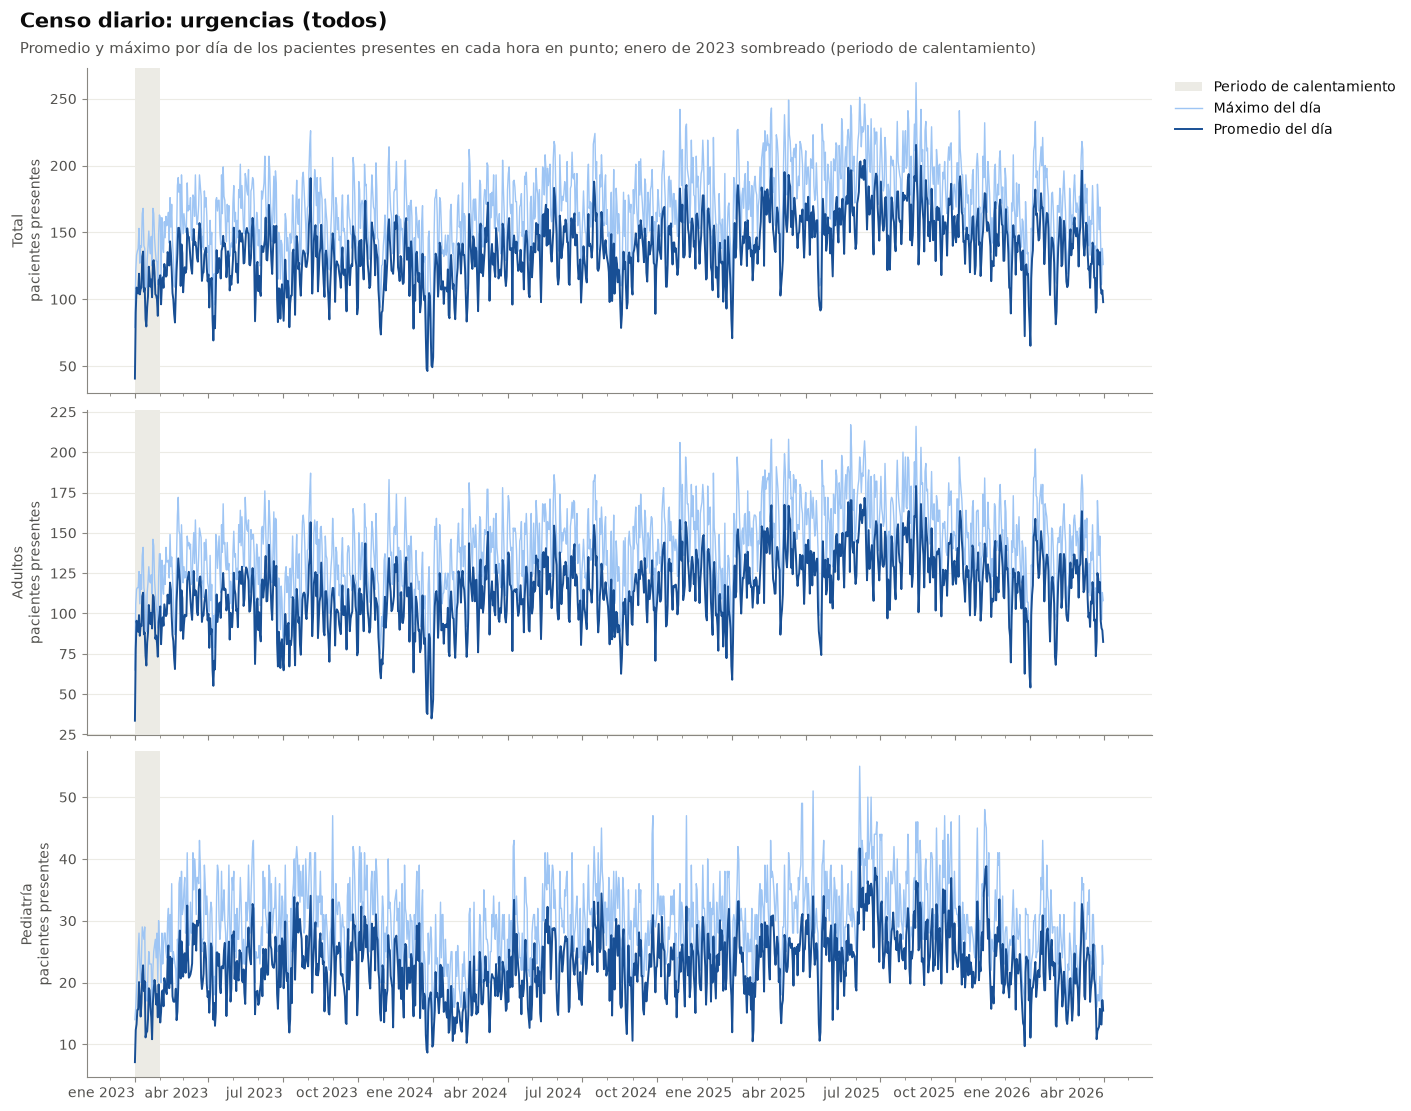

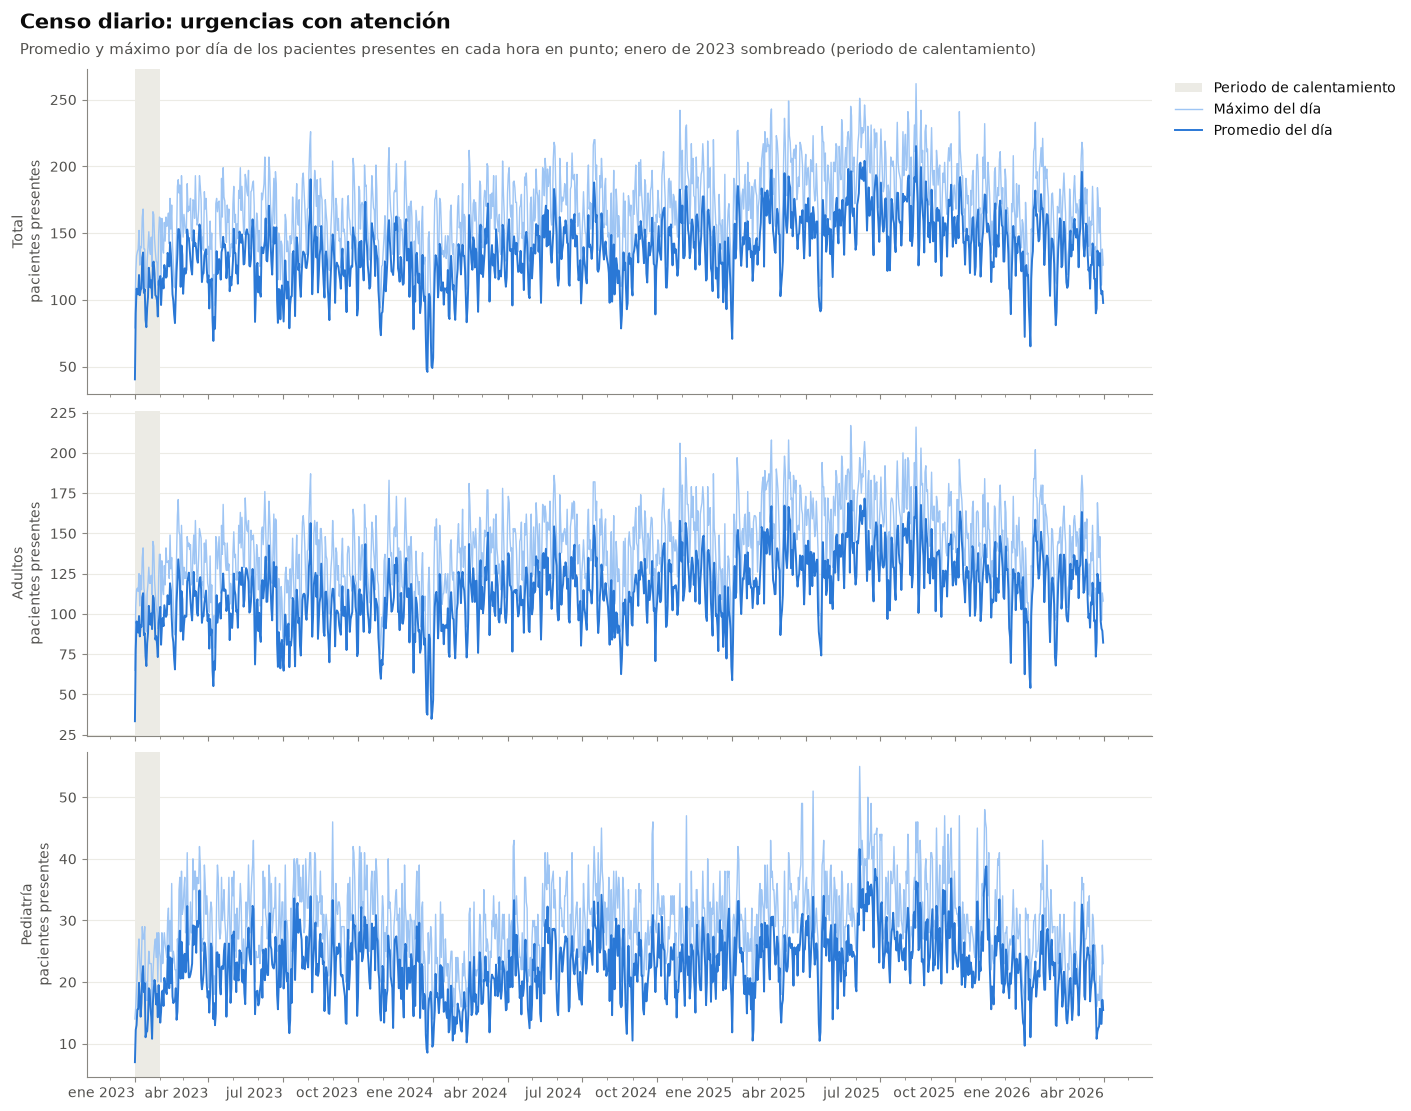

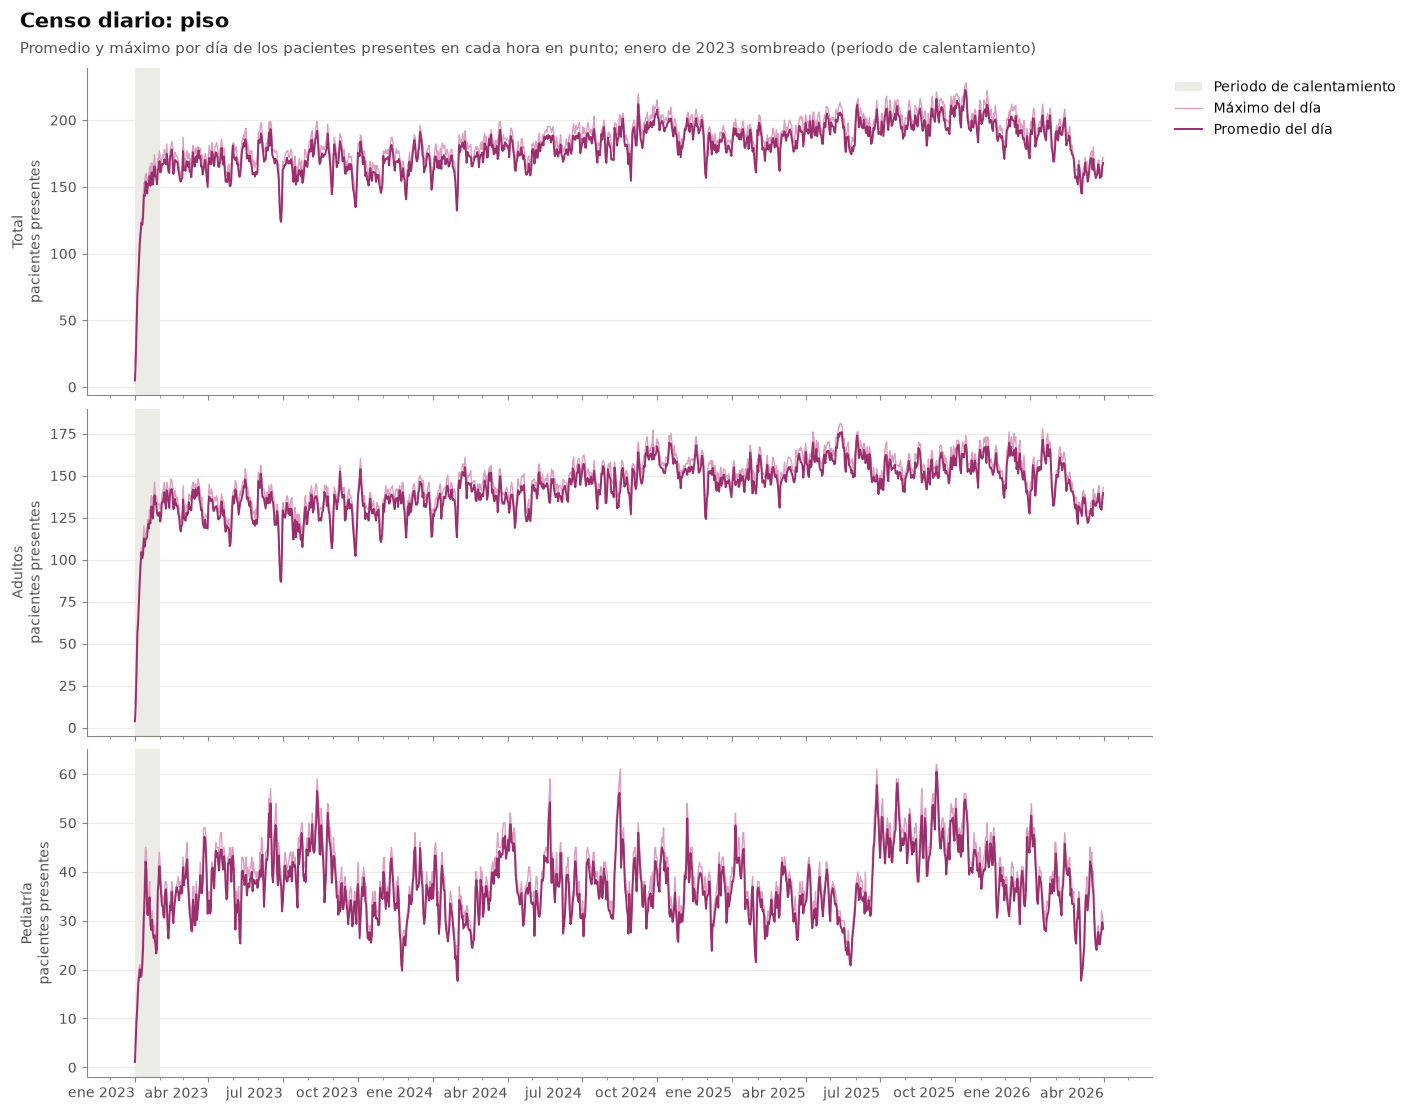

In [4]:
for area, censo in censos_completos.items():
    fig, ejes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
    for ax, grupo in zip(ejes, GRUPOS_CENSO):
        ax.axvspan(DESDE, INICIO_CENSO, color=estilo.RAMPA_GRIS[1], linewidth=0, zorder=0,
                   label='Periodo de calentamiento')
        diario = oc.resumen_diario(censo[grupo])
        ax.plot(diario.index, diario['maximo'], color=COLOR_CLARO_AREA[area], linewidth=1, label='Máximo del día')
        ax.plot(diario.index, diario['promedio'], color=COLOR_AREA[area], linewidth=1.4, label='Promedio del día')
        ax.set_ylabel(f'{NOMBRE_EDAD[grupo]}\npacientes presentes')
    leyenda_fuera(ejes[0])
    titulo_hallazgo(fig, f'Censo diario: {NOMBRE_AREA[area].lower()}',
                    'Promedio y máximo por día de los pacientes presentes en cada hora en punto; enero de 2023 sombreado (periodo de calentamiento)')
    guardar_figura(fig, f'06_censo_diario_{area}')
    plt.show()

## 2. Comprobación de capacidad

Máximo y percentil 95 mensual del censo frente a la capacidad actual (2026) entregada por el hospital: piso 72 camas (64 adultos y 8 pediatría) y 102 con cuidados especiales; observación de urgencias 58 camas (44 adultos y 14 pediatría).

In [5]:
for area in ('piso', 'urgencias_atencion'):
    mensual = pd.concat({grupo: oc.resumen_mensual(censos[area][grupo])[['maximo', 'p95']] for grupo in GRUPOS_CENSO},
                        axis=1)
    mensual.columns = [f'{medida}_{grupo}' for grupo, medida in mensual.columns]
    mensual.index = mensual.index.strftime('%Y-%m')
    mostrar_tabla(mensual.round(1), f'{NOMBRE_AREA[area]}: máximo y percentil 95 mensual del censo horario')

**Piso: máximo y percentil 95 mensual del censo horario**

,maximo_total,p95_total,maximo_adultos,p95_adultos,maximo_pediatria,p95_pediatria
mes,,,,,,
2023-02,184,180,148,145,41,38
2023-03,187,179,148,144,49,47
2023-04,186,181,145,139,48,45
2023-05,194,187,154,147,45,42
2023-06,199,195,156,149,57,53
2023-07,178,176,138,136,50,47
2023-08,199,192,145,142,59,"54,90"
2023-09,190,184,156,145,47,43
2023-10,189,182,160,150,42,38


**Urgencias con atención: máximo y percentil 95 mensual del censo horario**

,maximo_total,p95_total,maximo_adultos,p95_adultos,maximo_pediatria,p95_pediatria
mes,,,,,,
2023-02,193,171,171,"141,40",38,30
2023-03,193,172,158,140,42,36
2023-04,199,166,168,136,39,32
2023-05,199,178,172,"148,90",43,34
2023-06,207,177,176,148,39,33
2023-07,195,164,161,132,40,36
2023-08,226,184,187,"150,90",46,36
2023-09,206,168,165,137,42,33
2023-10,201,178,168,145,42,36


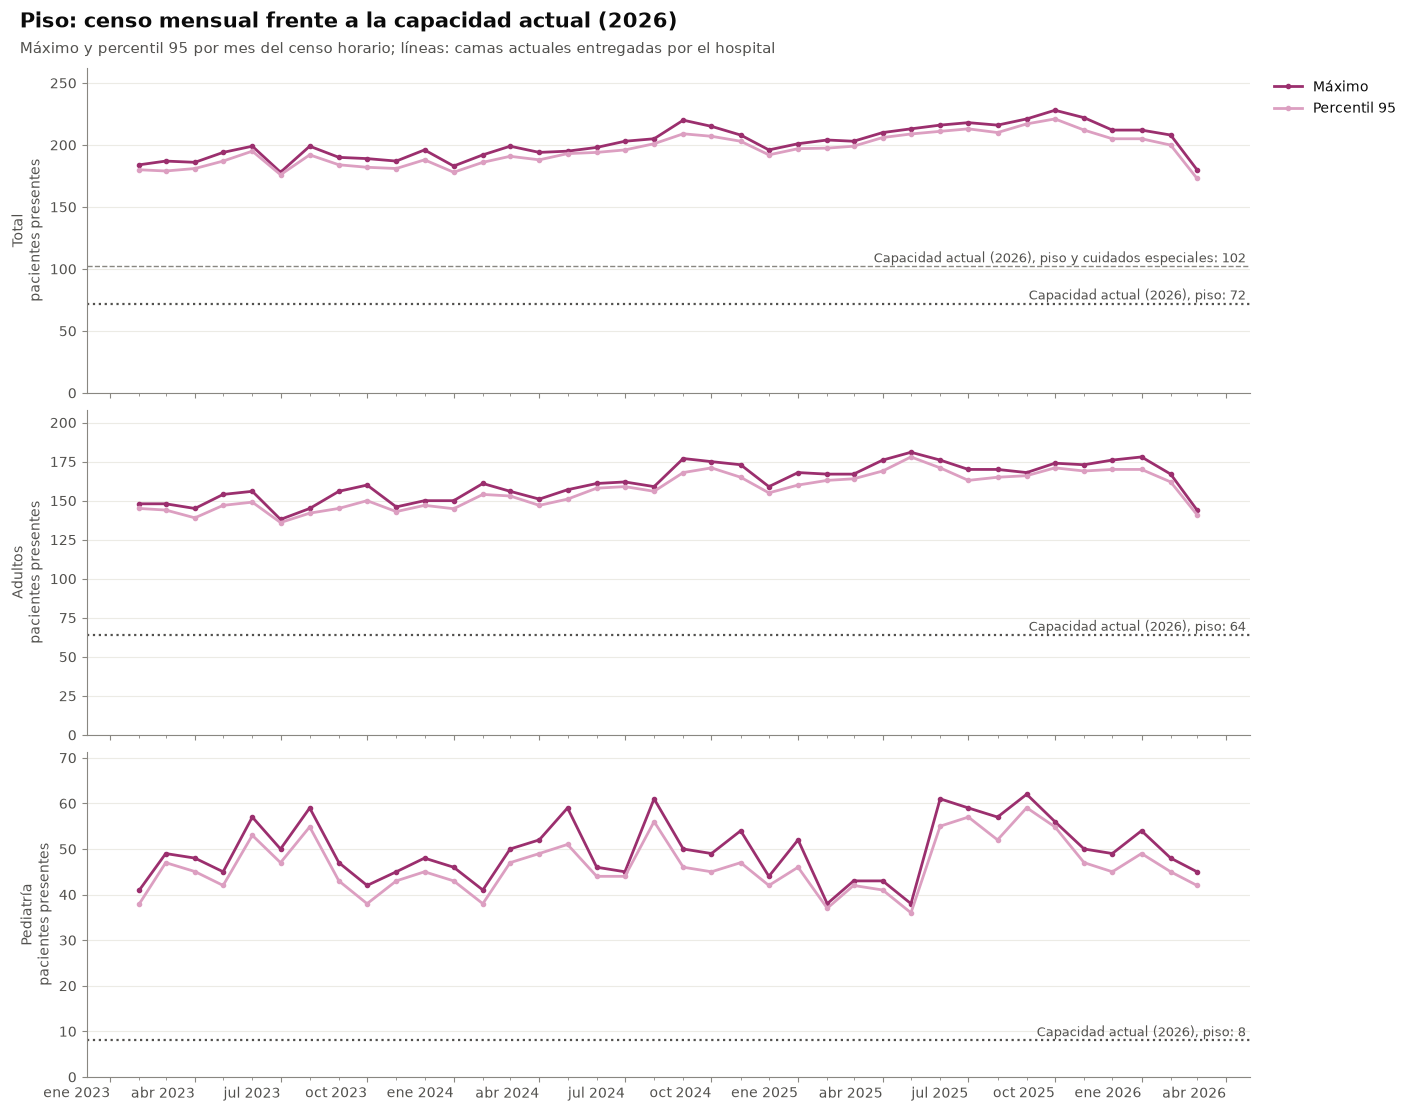

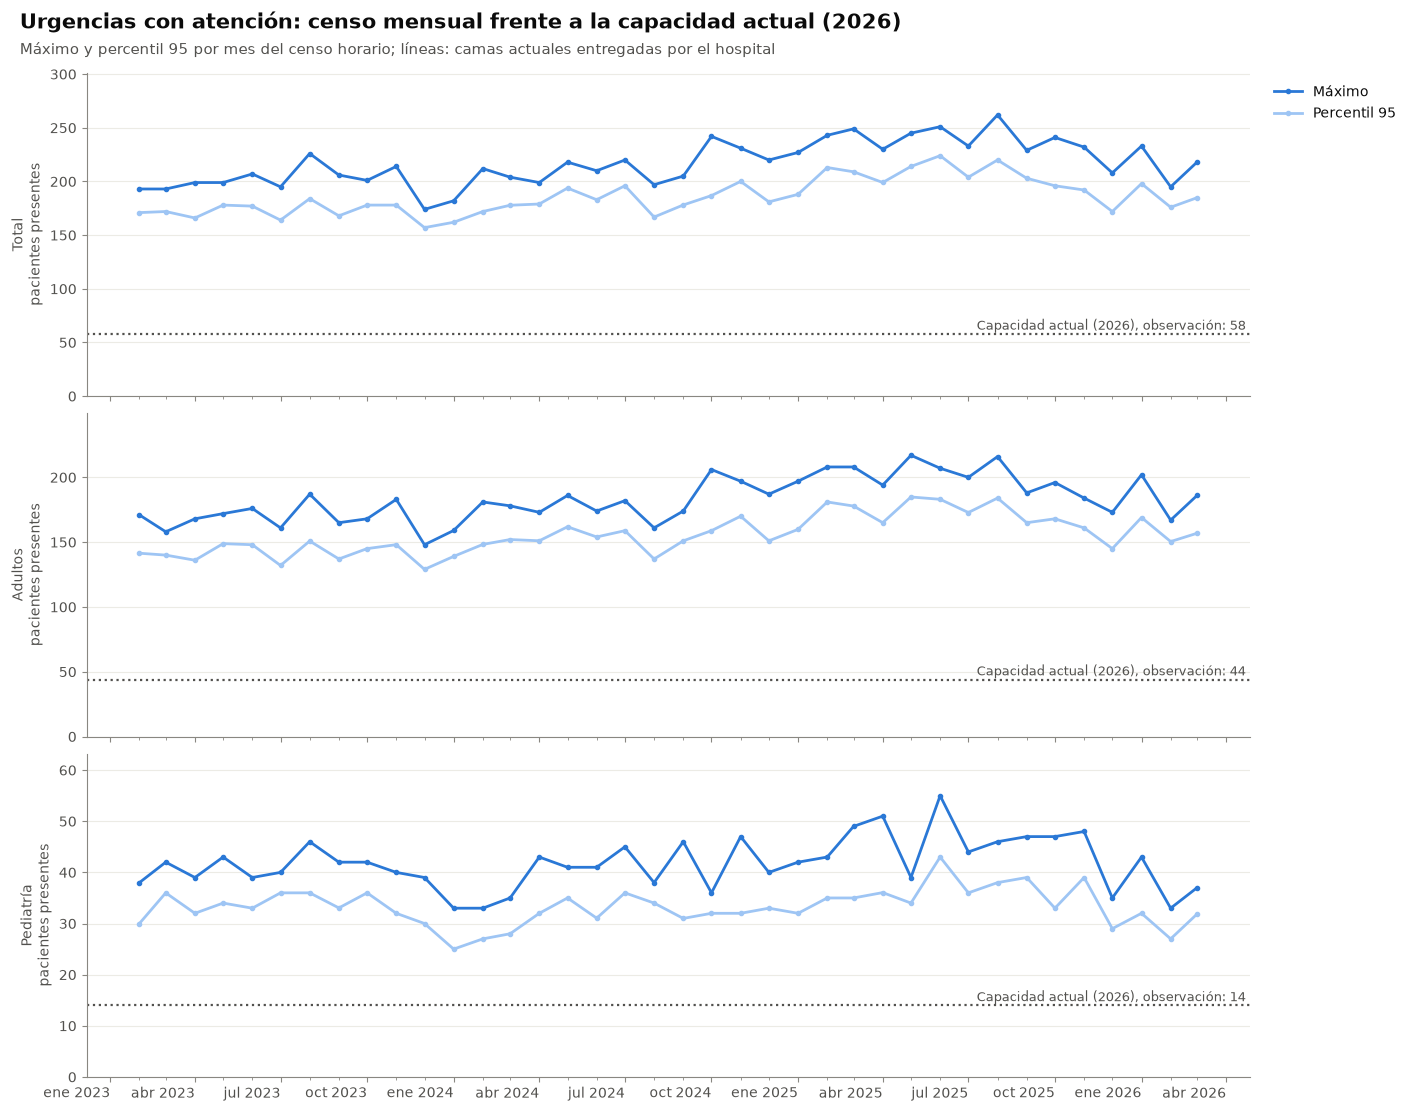

In [6]:
for area in ('piso', 'urgencias_atencion'):
    fig, ejes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
    for ax, grupo in zip(ejes, GRUPOS_CENSO):
        mensual = oc.resumen_mensual(censos[area][grupo])
        ax.plot(mensual.index, mensual['maximo'], marker='o', markersize=3, color=COLOR_AREA[area], label='Máximo')
        ax.plot(mensual.index, mensual['p95'], marker='o', markersize=3, color=COLOR_CLARO_AREA[area],
                label='Percentil 95')
        for fila, (etiqueta, camas) in enumerate(CAPACIDAD[area][grupo].items()):
            linea_umbral(ax, camas, f'Capacidad actual (2026), {NOMBRE_CAPACIDAD[etiqueta]}: {camas}', eje='y',
                         destacada=fila == 0)
        tope = max(mensual['maximo'].max(), max(CAPACIDAD[area][grupo].values()))
        ax.set_ylim(0, tope * 1.15)
        ax.set_ylabel(f'{NOMBRE_EDAD[grupo]}\npacientes presentes')
    leyenda_fuera(ejes[0])
    titulo_hallazgo(fig, f'{NOMBRE_AREA[area]}: censo mensual frente a la capacidad actual (2026)',
                    'Máximo y percentil 95 por mes del censo horario; líneas: camas actuales entregadas por el hospital')
    guardar_figura(fig, f'06_capacidad_{area}')
    plt.show()

## 3. Medidas de ocupación

Tres medidas para urgencias con atención y piso: absoluta (pacientes presentes), relativa (percentil de la hora dentro de su trimestre) y, como complemento, el porcentaje sobre la capacidad actual (2026).

### 3.1 Ocupación absoluta

Distribución del censo horario total.

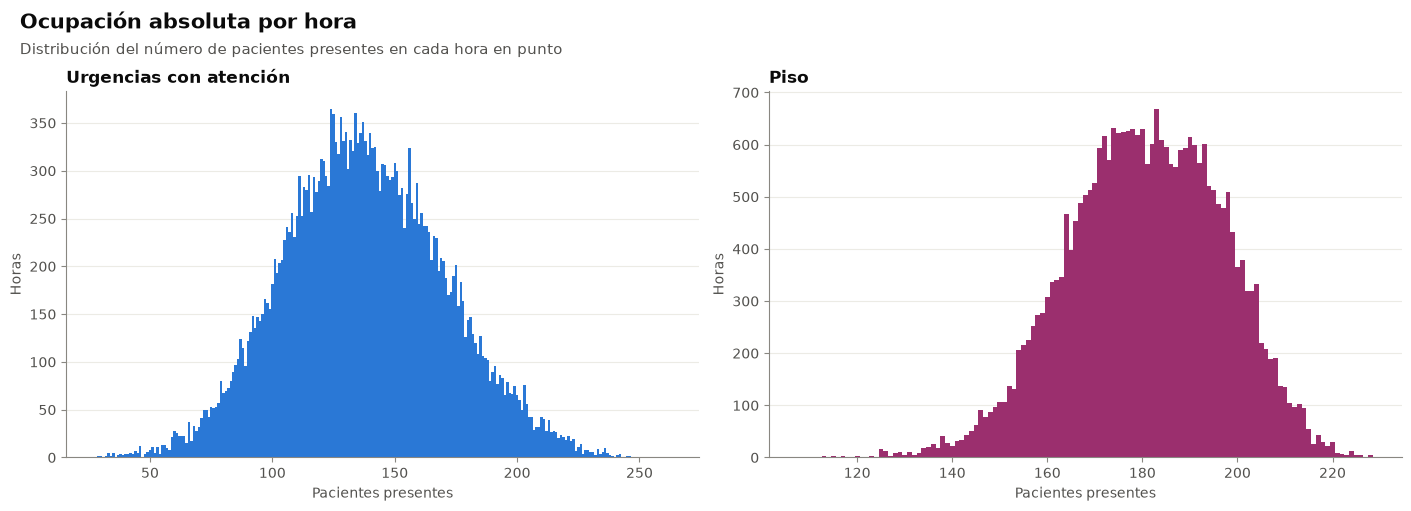

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, area in zip(ejes, AREAS_MEDIDAS):
    censo = censos[area]['total']
    ax.hist(censo, bins=np.arange(censo.min(), censo.max() + 2) - 0.5, color=COLOR_AREA[area])
    ax.set_xlabel('Pacientes presentes')
    ax.set_ylabel('Horas')
    ax.set_title(NOMBRE_AREA[area], loc='left')
titulo_hallazgo(fig, 'Ocupación absoluta por hora', 'Distribución del número de pacientes presentes en cada hora en punto')
guardar_figura(fig, '06_ocupacion_absoluta')
plt.show()

### 3.2 Ocupación relativa

Percentiles 50 y 90 del censo en cada trimestre: la referencia con la que se calcula el percentil de cada hora.

In [8]:
referencias = {}
for area in AREAS_MEDIDAS:
    censo = censos[area]['total']
    trimestre = censo.groupby(censo.index.to_period('Q'))
    referencias[f'p50_{area}'] = trimestre.quantile(0.5)
    referencias[f'p90_{area}'] = trimestre.quantile(0.9)
referencias = pd.DataFrame(referencias)
referencias.index = referencias.index.astype(str).rename('trimestre')
mostrar_tabla(referencias.round(1), 'Percentiles 50 y 90 del censo horario por trimestre')

**Percentiles 50 y 90 del censo horario por trimestre**

,p50_urgencias_atencion,p90_urgencias_atencion,p50_piso,p90_piso
trimestre,,,,
2023Q1,127,163,168,177
2023Q2,126,166,170,184
2023Q3,122,163,169,182
2023Q4,120,164,166,181
2024Q1,124,161,174,185
2024Q2,139,175,178,190
2024Q3,131,171,187,200
2024Q4,137,180,189,201
2025Q1,151,196,185,195


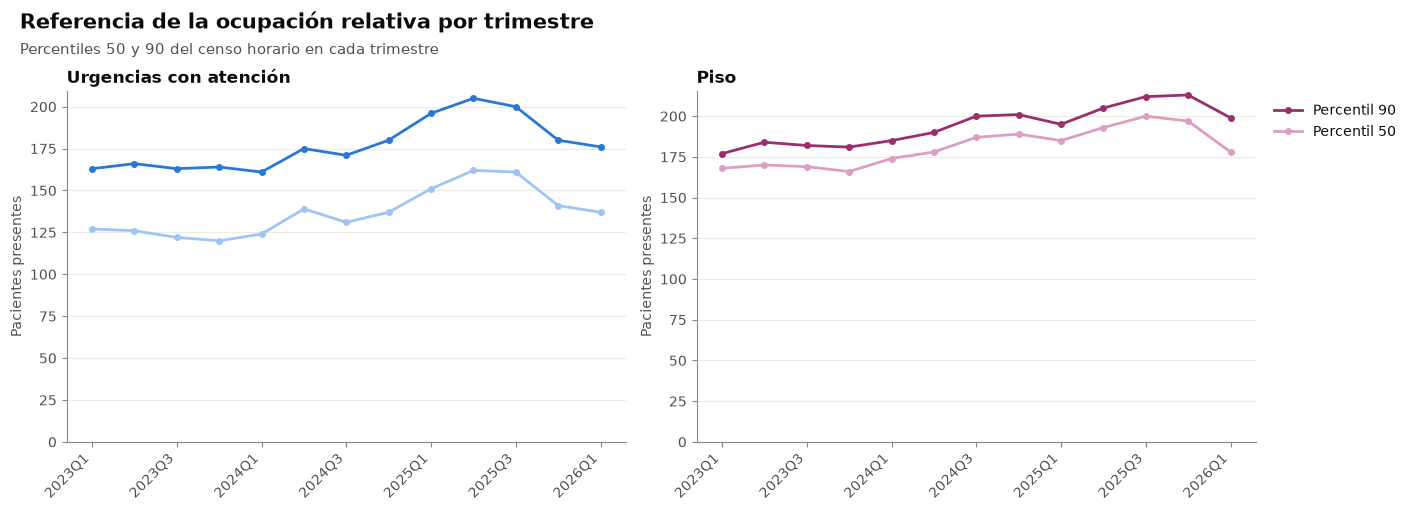

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
x = np.arange(len(referencias))
for ax, area in zip(ejes, AREAS_MEDIDAS):
    ax.plot(x, referencias[f'p90_{area}'], marker='o', markersize=4, color=COLOR_AREA[area], label='Percentil 90')
    ax.plot(x, referencias[f'p50_{area}'], marker='o', markersize=4, color=COLOR_CLARO_AREA[area], label='Percentil 50')
    ax.set_xticks(x[::2], referencias.index[::2], rotation=45, ha='right')
    ax.set_ylabel('Pacientes presentes')
    ax.set_title(NOMBRE_AREA[area], loc='left')
    ax.set_ylim(bottom=0)
leyenda_fuera(ejes[1])
titulo_hallazgo(fig, 'Referencia de la ocupación relativa por trimestre',
                'Percentiles 50 y 90 del censo horario en cada trimestre')
guardar_figura(fig, '06_ocupacion_relativa')
plt.show()

### 3.3 Ocupación sobre la capacidad actual (2026)

Censo horario como porcentaje de las camas actuales (2026) y resumen de las tres medidas por área y grupo de edad. Para piso, las medidas sobre la capacidad se calculan solo si `USAR_CAPACIDAD_PISO` es True.

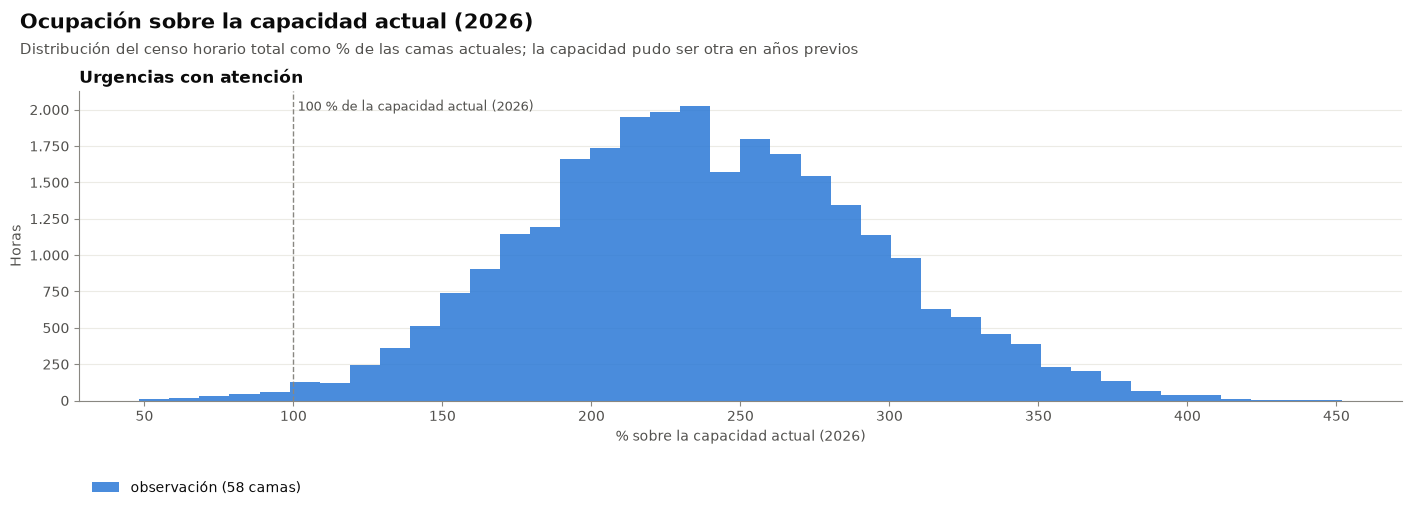

In [10]:
areas_capacidad = [area for area in AREAS_MEDIDAS if USAR_CAPACIDAD[area]]
fig, ejes = plt.subplots(1, len(areas_capacidad), figsize=(14, 5), squeeze=False)
for ax, area in zip(ejes[0], areas_capacidad):
    capacidades = CAPACIDAD[area]['total']
    for posicion, (etiqueta, camas) in enumerate(capacidades.items()):
        pct = 100 * censos[area]['total'] / camas
        color = COLOR_AREA[area] if posicion == 0 else COLOR_CLARO_AREA[area]
        ax.hist(pct, bins=40, color=color, alpha=0.85 if posicion == 0 else 0.6,
                label=f'{NOMBRE_CAPACIDAD[etiqueta]} ({camas} camas)')
    linea_umbral(ax, 100, '100 % de la capacidad actual (2026)', destacada=False)
    ax.set_xlabel('% sobre la capacidad actual (2026)')
    ax.set_ylabel('Horas')
    ax.set_title(NOMBRE_AREA[area], loc='left')
    leyenda_fuera(ax, 'debajo', ncol=1, bbox_to_anchor=(0, -0.22))
titulo_hallazgo(fig, 'Ocupación sobre la capacidad actual (2026)',
                'Distribución del censo horario total como % de las camas actuales; la capacidad pudo ser otra en años previos')
guardar_figura(fig, '06_ocupacion_capacidad_actual_2026')
plt.show()

In [11]:
for area in AREAS_MEDIDAS:
    capacidades = {grupo: CAPACIDAD[area][grupo] if USAR_CAPACIDAD[area] else {} for grupo in GRUPOS_CENSO}
    resumen = pd.DataFrame({NOMBRE_EDAD[grupo]: oc.resumen_ocupacion(censos[area][grupo], capacidades[grupo])
                            for grupo in GRUPOS_CENSO}).T.rename_axis('grupo_edad')
    sufijo = ' (% de horas sobre la capacidad actual (2026))' if USAR_CAPACIDAD[area] else ''
    mostrar_tabla(resumen.round(1), f'{NOMBRE_AREA[area]}: medidas de ocupación del censo horario{sufijo}')

**Urgencias con atención: medidas de ocupación del censo horario (% de horas sobre la capacidad actual (2026))**

,promedio,mediana,p90,maximo,pct_horas_sobre_90_capacidad_actual_2026_observacion,pct_horas_sobre_100_capacidad_actual_2026_observacion
grupo_edad,,,,,,
Total,"137,60",136,181,262,"99,6","99,4"
Adultos,"114,80",114,152,217,"99,7","99,5"
Pediatría,"22,80",22,32,55,"94,4","88,7"


**Piso: medidas de ocupación del censo horario**

,promedio,mediana,p90,maximo
grupo_edad,,,,
Total,"180,60",181,201,228
Adultos,"143,40",144,162,181
Pediatría,"37,20",37,46,62


## 4. Patrones

Censo promedio por hora del día y día de la semana, y serie mensual del promedio y el percentil 90.

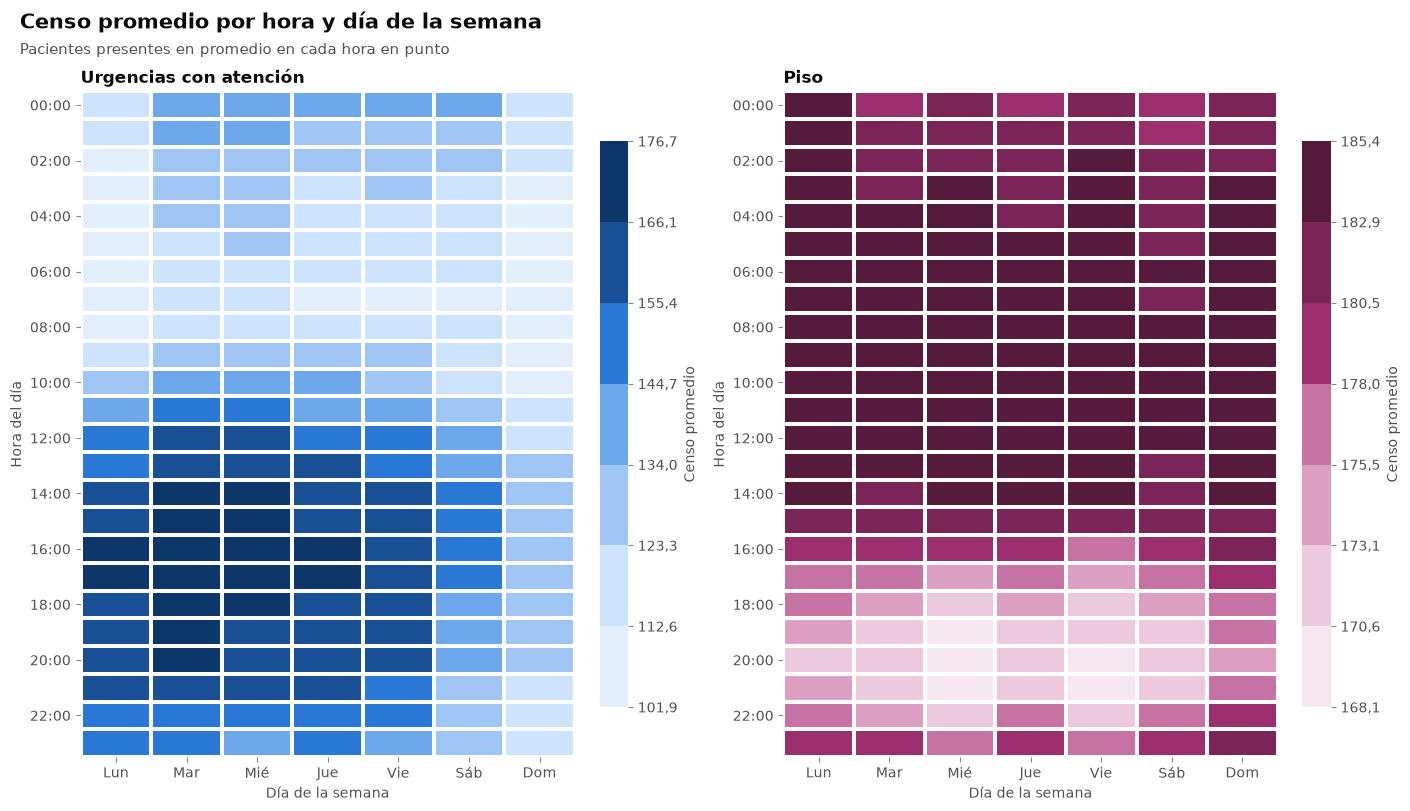

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 8))
for ax, area in zip(ejes, AREAS_MEDIDAS):
    heatmap_hora_dia(ax, oc.matriz_hora_dia(censos[area]['total']), NOMBRE_AREA[area], 'Censo promedio',
                     familia=FAMILIA_AREA[area])
    ax.set_xlabel('Día de la semana')
    ax.set_ylabel('Hora del día')
titulo_hallazgo(fig, 'Censo promedio por hora y día de la semana', 'Pacientes presentes en promedio en cada hora en punto')
guardar_figura(fig, '06_censo_hora_dia')
plt.show()

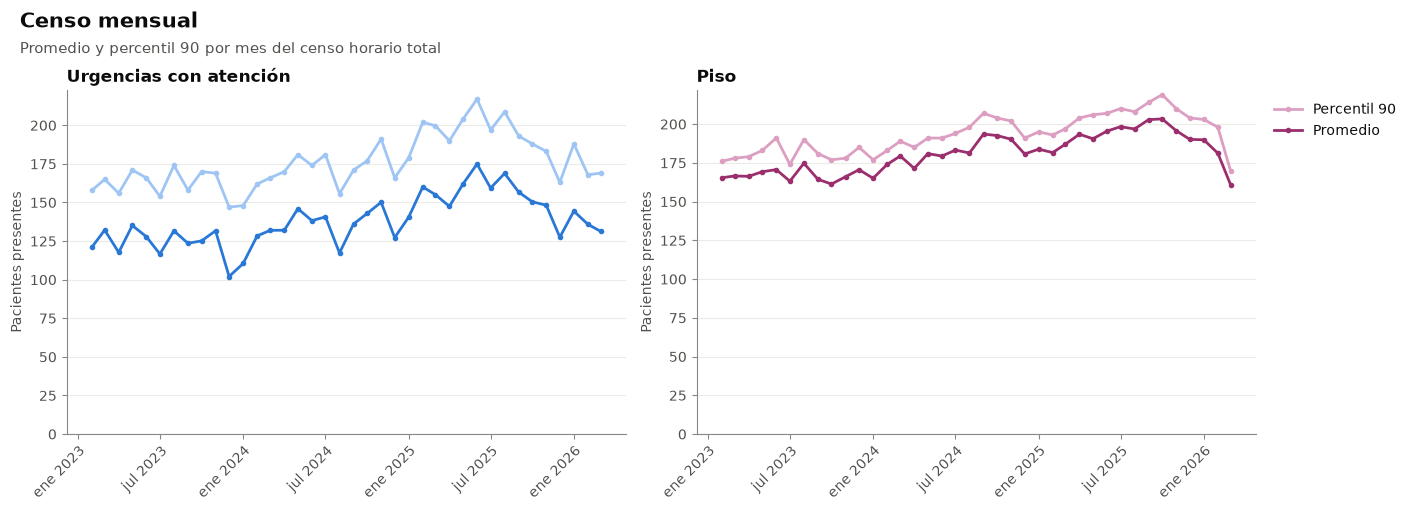

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, area in zip(ejes, AREAS_MEDIDAS):
    mensual = oc.resumen_mensual(censos[area]['total'])
    ax.plot(mensual.index, mensual['p90'], marker='o', markersize=3, color=COLOR_CLARO_AREA[area], label='Percentil 90')
    ax.plot(mensual.index, mensual['promedio'], marker='o', markersize=3, color=COLOR_AREA[area], label='Promedio')
    ax.set_ylabel('Pacientes presentes')
    ax.set_title(NOMBRE_AREA[area], loc='left')
    ax.set_ylim(bottom=0)
    formato_eje_fechas(ax.xaxis, paso=6)
leyenda_fuera(ejes[1])
titulo_hallazgo(fig, 'Censo mensual', 'Promedio y percentil 90 por mes del censo horario total')
guardar_figura(fig, '06_censo_mensual')
plt.show()

## 5. Saturación

Hora saturada: censo por encima del percentil 90 de su trimestre; día saturado: 3 o más horas saturadas. Como alternativa, horas por encima del 90 % de la capacidad actual (2026), con el mismo mínimo de horas. Para piso, la alternativa por capacidad se calcula solo si `USAR_CAPACIDAD_PISO` es True.

In [14]:
dias = {}
for area in AREAS_MEDIDAS:
    censo = censos[area]['total']
    camas = next(iter(CAPACIDAD[area]['total'].values()))
    dias[f'p90_trimestre_{area}'] = oc.dias_saturados(oc.horas_saturadas(censo))
    if USAR_CAPACIDAD[area]:
        dias[f'sobre_90_capacidad_actual_2026_{area}'] = oc.dias_saturados(censo.gt(0.9 * camas))
dias = pd.DataFrame(dias)

saturacion_mes = pd.concat({f'pct_dias_{columna}': oc.pct_dias_por(dias[columna], 'mes') for columna in dias}, axis=1)
saturacion_mes.insert(0, 'dias', dias.groupby(dias.index.to_period('M').to_timestamp()).size())
saturacion_mes.index = saturacion_mes.index.strftime('%Y-%m')
camas_usadas = '; '.join(f'{NOMBRE_AREA[area].lower()}: {next(iter(CAPACIDAD[area]["total"].values()))} camas'
                         for area in AREAS_MEDIDAS if USAR_CAPACIDAD[area])
mostrar_tabla(saturacion_mes.round(1), f'% de días saturados por mes (capacidad actual (2026) usada: {camas_usadas})')

**% de días saturados por mes (capacidad actual (2026) usada: urgencias con atención: 58 camas)**

,dias,pct_dias_p90_trimestre_urgencias_atencion,pct_dias_sobre_90_capacidad_actual_2026_urgencias_atencion,pct_dias_p90_trimestre_piso
mes,,,,
2023-02,28,"21,4","100,0","14,3"
2023-03,31,"35,5","100,0","22,6"
2023-04,30,"16,7","100,0","3,3"
2023-05,31,"48,4","100,0","9,7"
2023-06,30,"33,3","100,0","33,3"
2023-07,31,"22,6","100,0","0,0"
2023-08,31,"48,4","100,0","38,7"
2023-09,30,"26,7","100,0","16,7"
2023-10,31,"38,7","100,0","9,7"


In [15]:
saturacion_dia = pd.concat({f'pct_dias_{columna}': oc.pct_dias_por(dias[columna], 'dia_semana') for columna in dias},
                           axis=1)
saturacion_dia.insert(0, 'dias', dias.groupby(dias.index.dayofweek).size())
saturacion_dia.index = pd.Index(estilo.DIAS_SEMANA_COMPLETOS, name='dia_semana')
mostrar_tabla(saturacion_dia.round(1), '% de días saturados por día de la semana')

**% de días saturados por día de la semana**

,dias,pct_dias_p90_trimestre_urgencias_atencion,pct_dias_sobre_90_capacidad_actual_2026_urgencias_atencion,pct_dias_p90_trimestre_piso
dia_semana,,,,
lunes,165,"37,6","100,0","20,0"
martes,165,"55,8","100,0","18,8"
miércoles,165,"48,5","100,0","18,8"
jueves,165,"39,4","100,0","17,6"
viernes,165,"27,3","100,0","20,0"
sábado,165,"8,5","100,0","18,2"
domingo,165,"1,2","100,0","17,0"


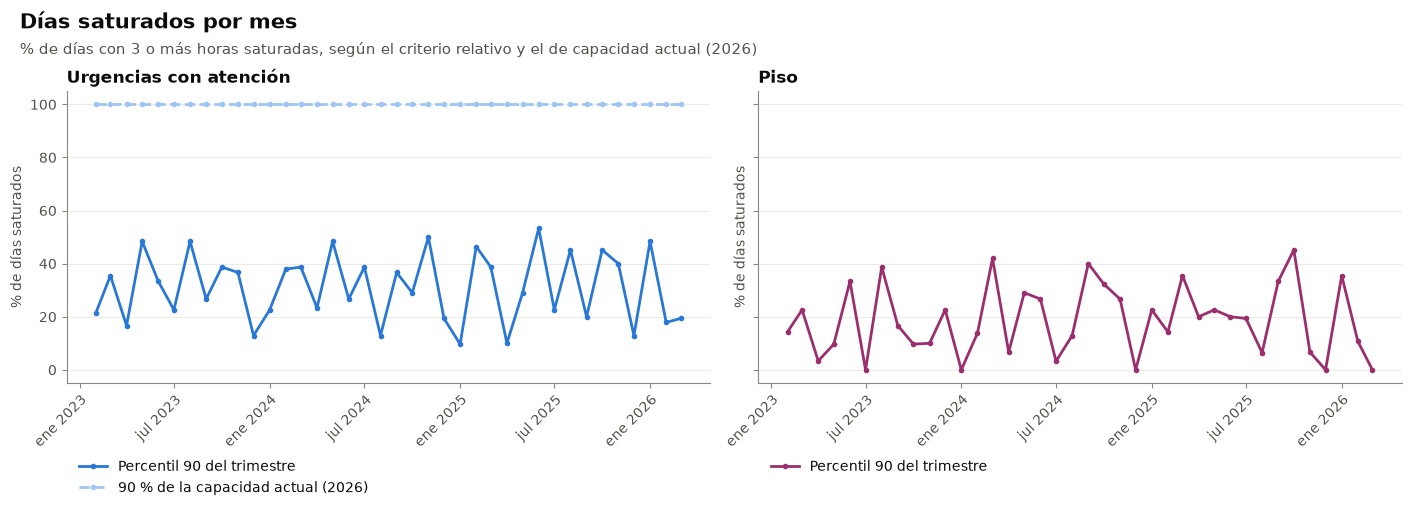

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
meses = pd.to_datetime(saturacion_mes.index)
for ax, area in zip(ejes, AREAS_MEDIDAS):
    ax.plot(meses, saturacion_mes[f'pct_dias_p90_trimestre_{area}'], marker='o', markersize=3, color=COLOR_AREA[area],
            label='Percentil 90 del trimestre')
    if USAR_CAPACIDAD[area]:
        ax.plot(meses, saturacion_mes[f'pct_dias_sobre_90_capacidad_actual_2026_{area}'], marker='o', markersize=3,
                color=COLOR_CLARO_AREA[area], linestyle='--', label='90 % de la capacidad actual (2026)')
    ax.set_ylabel('% de días saturados')
    formato_eje_fechas(ax.xaxis, paso=6)
    ax.set_title(NOMBRE_AREA[area], loc='left')
    leyenda_fuera(ax, 'debajo', ncol=1, bbox_to_anchor=(0, -0.22))
titulo_hallazgo(fig, 'Días saturados por mes',
                '% de días con 3 o más horas saturadas, según el criterio relativo y el de capacidad actual (2026)')
guardar_figura(fig, '06_dias_saturados_mes')
plt.show()

## 6. Ocupación del piso y tiempo en urgencias

Para cada episodio de atención en urgencias u hospitalizado válido para tiempos, ocupación del piso en la hora de llegada y en promedio durante su permanencia en urgencias; LOS por decil de ocupación relativa. Adultos se comparan con el piso de adultos y pediatría con el piso pediátrico.

In [17]:
cohorte = episodios[episodios['en_poblacion'] & episodios['valido_para_tiempos'].astype(bool)
                    & episodios['grupo'].isin([G2, G3]) & episodios['los_h'].notna()
                    & episodios['llegada'].ge(INICIO_CENSO)].copy()
cohorte['grupo_edad'] = oc.grupo_edad(cohorte['edad'])
MEDIDAS_EPISODIO = {'llegada': 'en la llegada', 'estancia': 'promedio durante la permanencia'}

por_decil = []
for grupo in GRUPOS_CENSO:
    parte = cohorte if grupo == 'total' else cohorte[cohorte['grupo_edad'].eq(grupo)]
    ocupacion_piso = oc.ocupacion_en_episodios(parte, censos['piso'][grupo])
    for medida in MEDIDAS_EPISODIO:
        deciles = oc.decil(ocupacion_piso[f'rel_{medida}']).rename('decil')
        tabla = oc.tabla_por_decil(parte, deciles)
        piso_mediano = ocupacion_piso[f'abs_{medida}'].groupby([parte['grupo'], deciles]).median()
        tabla = tabla.merge(piso_mediano.rename('censo_piso_mediano').reset_index(), on=['grupo', 'decil'], how='left')
        tabla.insert(0, 'medida', medida)
        tabla.insert(1, 'grupo_edad', grupo)
        por_decil.append(tabla)
por_decil = pd.concat(por_decil, ignore_index=True)

In [18]:
for medida, nombre in MEDIDAS_EPISODIO.items():
    for grupo in GRUPOS_CENSO:
        tabla = por_decil[por_decil['medida'].eq(medida) & por_decil['grupo_edad'].eq(grupo)].drop(
            columns=['medida', 'grupo_edad'])
        mostrar_tabla(tabla_segura(tabla.set_index(['grupo', 'decil']), decimales=1),
                      f'{NOMBRE_EDAD[grupo]}: LOS por decil de ocupación relativa del piso {nombre}')

**Total: LOS por decil de ocupación relativa del piso en la llegada**

n mediana_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h censo_piso_mediano
grupo                decil                                                                                         
2_atencion_urgencias 1      16.377         6     4.068        24,8           24,2           25,5                158
                     2      16.917      6,50     4.417        26,1           25,5           26,8                168
                     3      17.516      6,50     4.526        25,8           25,2           26,5                171
                     4      16.453      6,60     4.452        27,1           26,4           27,7                174
                     5      18.160      6,70     4.871        26,8           26,2           27,5                183
                     6      17.892      6,60     4.936        27,6           26,9           28,2                184
                     7      19.637      6,90     5.371        27,4           26,7           28,0                186
                     8      20.262      6,90     5.753        28,4           27,8           29,0                190
                     9      20.556      7,10     5.895        28,7           28,1           29,3                192
                     10     23.450      7,20     6.454        27,5           27,0           28,1                199
3_hospitalizado      1       2.875     21,40     1.884        65,5           63,8           67,2                157
                     2       3.142     22,60     2.084        66,3           64,7           68,0                167
                     3       3.289        24     2.237        68,0           66,4           69,6                171
                     4       2.932     22,10     1.930        65,8           64,1           67,5                173
                     5       3.279     22,80     2.154        65,7           64,0           67,3                177
                     6       3.263     23,60     2.197        67,3           65,7           68,9                185
                     7       3.487     26,30     2.427        69,6           68,1           71,1                187
                     8       3.630     25,90     2.533        69,8           68,3           71,3                190
                     9       3.592     26,40     2.519        70,1           68,6           71,6                193
                     10      4.066     27,20     2.878        70,8           69,4           72,2                198

**Adultos: LOS por decil de ocupación relativa del piso en la llegada**

n mediana_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h censo_piso_mediano
grupo                decil                                                                                         
2_atencion_urgencias 1      11.551      7,20     3.110        26,9           26,1           27,7                125
                     2      12.461      7,50     3.709        29,8           29,0           30,6                131
                     3      11.381      7,40     3.101        27,2           26,4           28,1                135
                     4      14.659      7,60     4.364        29,8           29,0           30,5                138
                     5      13.633      7,70     4.093        30,0           29,3           30,8                140
                     6      13.625      7,50     4.015        29,5           28,7           30,2                149
                     7      12.722      7,80     3.910        30,7           29,9           31,5                144
                     8      16.689         8     5.353        32,1           31,4           32,8                153
                     9      15.383      7,90     4.723        30,7           30,0           31,4                156
                     10     17.242      7,90     5.248        30,4           29,8           31,1                162
3_hospitalizado      1       2.202     23,50     1.520        69,0           67,1           70,9                125
                     2       2.549     25,10     1.805        70,8           69,0           72,5                131
                     3       2.135     24,90     1.502        70,4           68,4           72,3                135
                     4       2.602     25,90     1.828        70,3           68,5           72,0                138
                     5       2.608     27,70     1.893        72,6           70,8           74,3                140
                     6       2.577     27,80     1.831        71,1           69,3           72,8                149
                     7       2.416     26,90     1.733        71,7           69,9           73,5                144
                     8       3.115        29     2.274        73,0           71,4           74,5                153
                     9       2.827     28,90     2.105        74,5           72,8           76,0                156
                     10      3.157        29     2.334        73,9           72,4           75,4                162

**Pediatría: LOS por decil de ocupación relativa del piso en la llegada**

n mediana_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h censo_piso_mediano
grupo                decil                                                                                        
2_atencion_urgencias 1      3.871      1,30       726        18,8           17,6           20,0                 27
                     2      4.498      1,30       830        18,5           17,3           19,6                 30
                     3      3.928      1,70       730        18,6           17,4           19,8                 32
                     4      4.602      2,20       885        19,2           18,1           20,4                 33
                     5      5.239      1,20       976        18,6           17,6           19,7                 35
                     6      4.705      1,60       913        19,4           18,3           20,6                 37
                     7      4.342      1,80       864        19,9           18,7           21,1                 38
                     8      5.347         2     1.059        19,8           18,8           20,9                 39
                     9      5.542      1,60     1.050        18,9           17,9           20,0                 42
                     10     5.800      1,30     1.084        18,7           17,7           19,7                 47
3_hospitalizado      1        572     13,40       306        53,5           49,4           57,5                 27
                     2        688     15,30       377        54,8           51,1           58,5                 30
                     3        657     13,80       362        55,1           51,3           58,9                 33
                     4        765     14,60       428        55,9           52,4           59,4                 34
                     5        837     13,10       436        52,1           48,7           55,5                 36
                     6        717     12,90       373        52,0           48,4           55,7                 37
                     7        609     16,50       359        58,9           55,0           62,8                 38
                     8        839     15,10       470        56,0           52,6           59,3                 40
                     9        810     13,20       426        52,6           49,1           56,0                 43
                     10       873     14,30       481        55,1           51,8           58,4                 47

... (2 outputs left out)

**Adultos: LOS por decil de ocupación relativa del piso promedio durante la permanencia**

n mediana_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h censo_piso_mediano
grupo                decil                                                                                         
2_atencion_urgencias 1       9.591      5,60     1.779        18,5           17,8           19,3                124
                     2      12.922      7,30     3.354        26,0           25,2           26,7             130,80
                     3      13.743      8,10     4.294        31,2           30,5           32,0             134,70
                     4      16.206      8,20     5.027        31,0           30,3           31,7             142,20
                     5      15.863      8,40     5.427        34,2           33,5           35,0             140,60
                     6      15.929      8,70     5.659        35,5           34,8           36,3             148,30
                     7      15.985         9     5.972        37,4           36,6           38,1             146,10
                     8      15.218      7,90     4.766        31,3           30,6           32,1                153
                     9      13.172         7     3.490        26,5           25,7           27,3                157
                     10     10.717      4,60     1.858        17,3           16,6           18,1                162
3_hospitalizado      1       1.559        14       862        55,3           52,8           57,7             123,80
                     2       2.331     22,70     1.538        66,0           64,0           67,9             129,80
                     3       2.656     27,50     1.929        72,6           70,9           74,3             133,60
                     4       3.016     26,10     2.180        72,3           70,7           73,8             141,30
                     5       3.505     30,70     2.723        77,7           76,3           79,0             145,80
                     6       3.473     28,60     2.641        76,0           74,6           77,4             144,40
                     7       3.291        31     2.553        77,6           76,1           79,0             144,50
                     8       2.856     28,60     2.122        74,3           72,7           75,9             147,80
                     9       2.238     26,70     1.578        70,5           68,6           72,4             157,40
                     10      1.263     14,90       699        55,3           52,6           58,1             162,40

**Pediatría: LOS por decil de ocupación relativa del piso promedio durante la permanencia**

n mediana_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h censo_piso_mediano
grupo                decil                                                                                        
2_atencion_urgencias 1      3.621      0,90       503        13,9           12,8           15,1                 27
                     2      4.486      1,20       783        17,5           16,4           18,6                 30
                     3      4.201         3       851        20,3           19,1           21,5                 32
                     4      4.743      2,40       960        20,2           19,1           21,4              33,50
                     5      5.325      1,70     1.058        19,9           18,8           21,0                 35
                     6      5.222      3,20     1.197        22,9           21,8           24,1              36,50
                     7      4.565      2,90     1.010        22,1           20,9           23,4                 38
                     8      5.192      1,40     1.014        19,5           18,5           20,6              39,80
                     9      5.340      1,20       988        18,5           17,5           19,6              42,10
                     10     5.179      0,60       753        14,5           13,6           15,5                 47
3_hospitalizado      1        471      8,80       199        42,3           37,9           46,8                 27
                     2        672     13,90       363        54,0           50,2           57,8              30,30
                     3        753     12,70       390        51,8           48,2           55,3              32,20
                     4        768     14,70       430        56,0           52,5           59,5              33,40
                     5        880     15,30       506        57,5           54,2           60,7              35,40
                     6        910     16,40       537        59,0           55,8           62,2              36,80
                     7        767     17,90       459        59,8           56,3           63,3                 38
                     8        781     14,40       428        54,8           51,3           58,3              40,30
                     9        729     13,70       394        54,0           50,4           57,6              42,70
                     10       636     11,60       312        49,1           45,2           52,9                 48

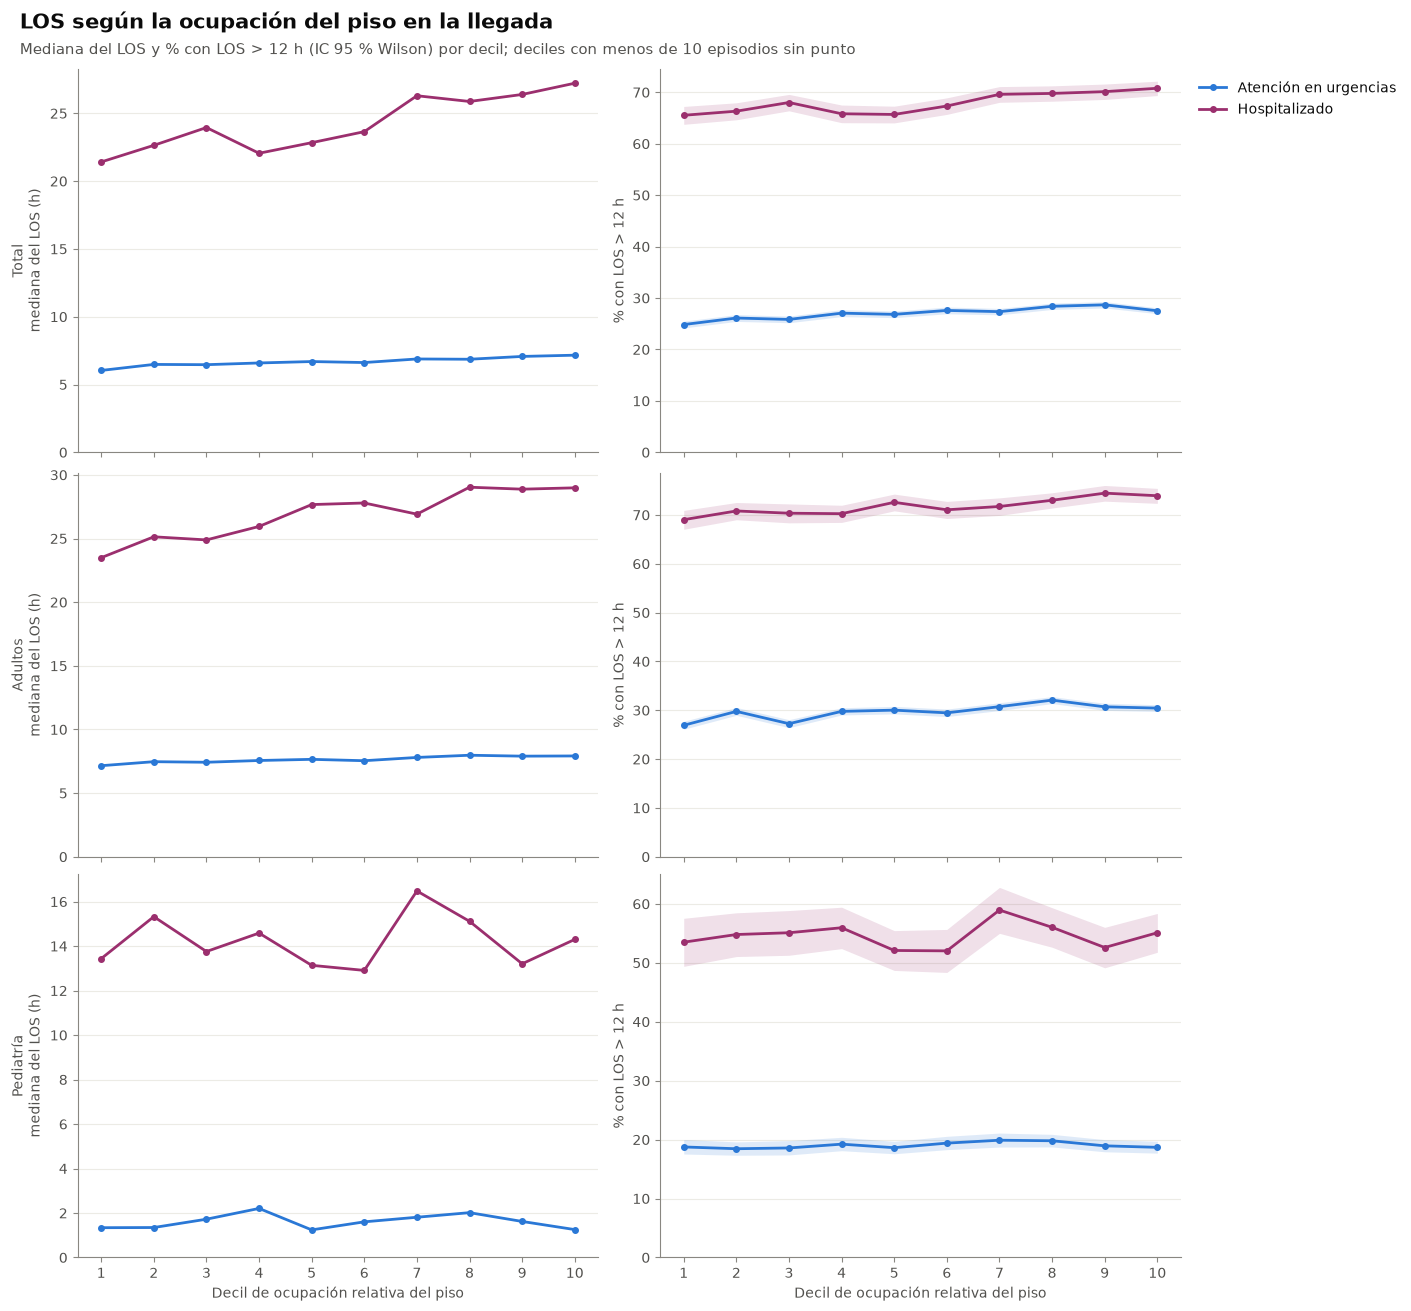

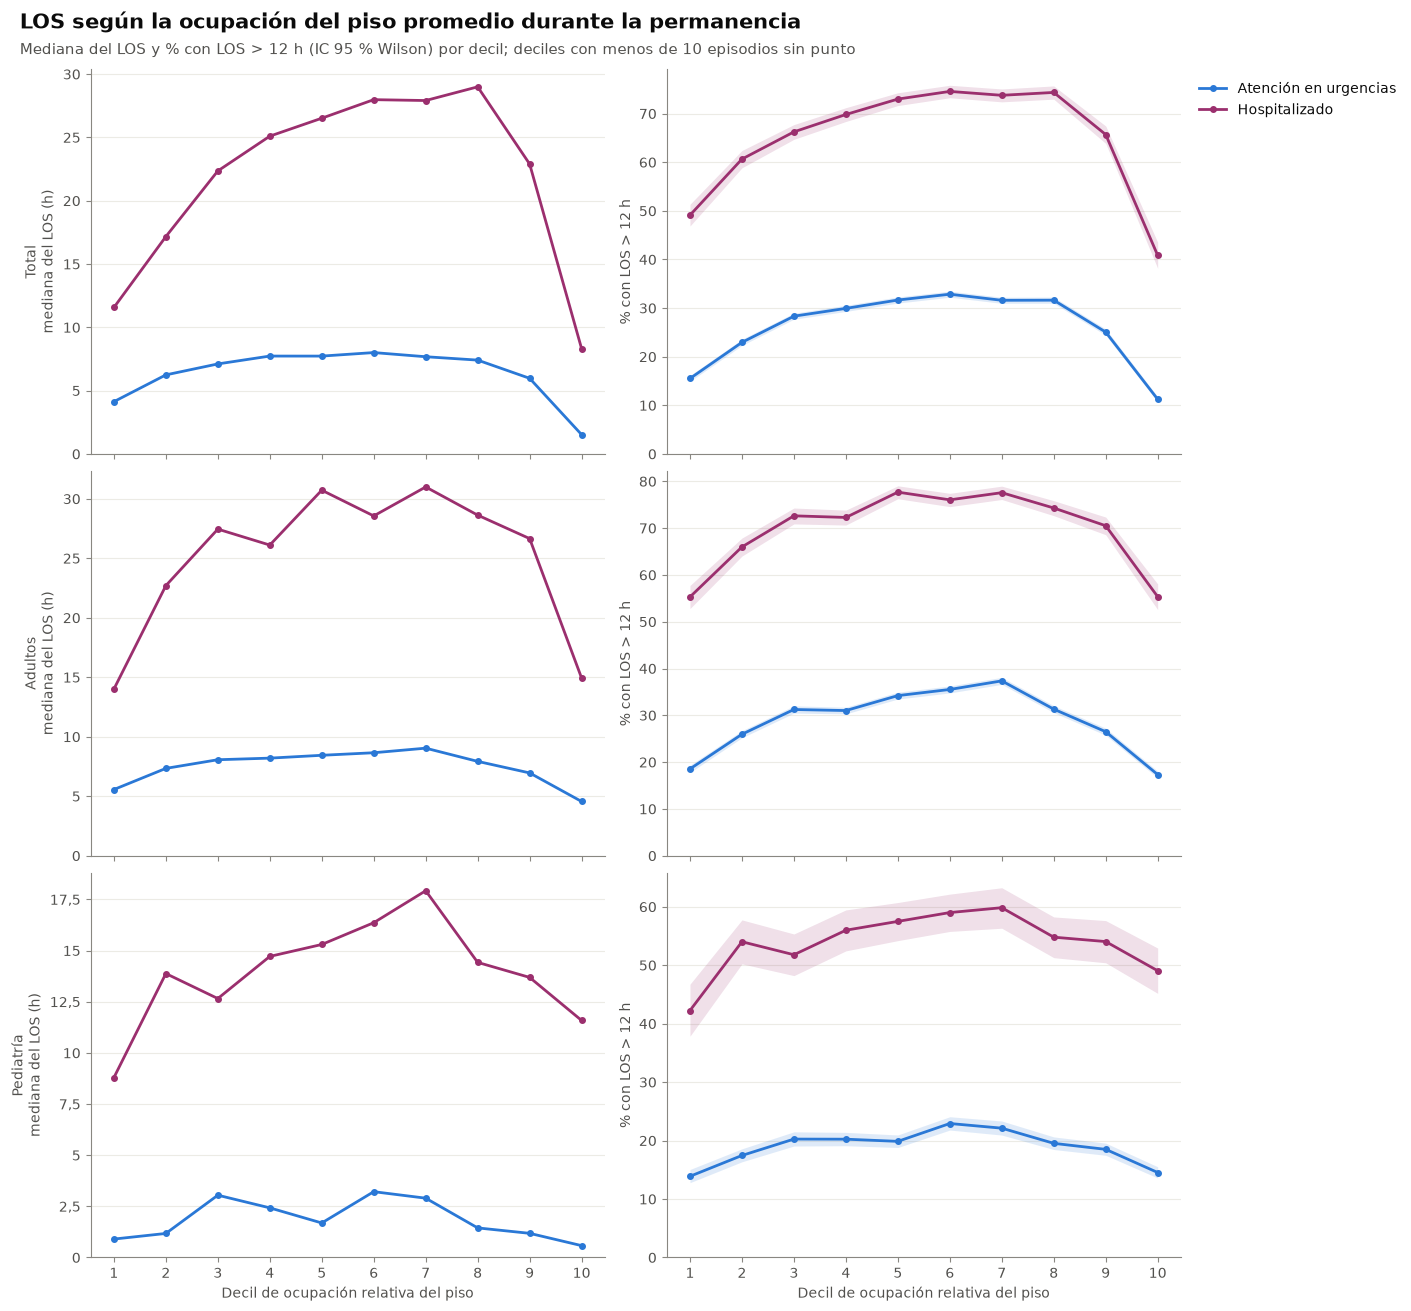

In [19]:
umbral = config.UMBRAL_OPERATIVO_H
for medida, nombre in MEDIDAS_EPISODIO.items():
    fig, ejes = plt.subplots(3, 2, figsize=(14, 13), sharex=True)
    for fila, grupo in enumerate(GRUPOS_CENSO):
        datos = por_decil[por_decil['medida'].eq(medida) & por_decil['grupo_edad'].eq(grupo)]
        for grupo_paciente in (G2, G3):
            d = datos[datos['grupo'].eq(grupo_paciente) & datos['decil'].notna()].sort_values('decil')
            x = d['decil'].astype(float)
            visible = d['n'].ge(config.MIN_CELDA)
            color = COLORES_GRUPO[grupo_paciente]
            etiqueta = estilo.ETIQUETA_CORTA_ROL[grupo_paciente]
            ejes[fila, 0].plot(x, d['mediana_h'].where(visible), marker='o', markersize=4, color=color,
                               label=etiqueta)
            ejes[fila, 1].plot(x, d[f'pct_mas_{umbral}h'].where(visible), marker='o', markersize=4,
                               color=color, label=etiqueta)
            ejes[fila, 1].fill_between(x, d[f'ic_inf_mas_{umbral}h'].where(visible),
                                       d[f'ic_sup_mas_{umbral}h'].where(visible), color=color, alpha=0.15, linewidth=0)
        ejes[fila, 0].set_ylabel(f'{NOMBRE_EDAD[grupo]}\nmediana del LOS (h)')
        ejes[fila, 1].set_ylabel(f'% con LOS > {umbral} h')
        ejes[fila, 0].set_ylim(bottom=0)
        ejes[fila, 1].set_ylim(bottom=0)
    for ax in ejes[-1]:
        ax.set_xticks(range(1, 11))
        ax.set_xlabel('Decil de ocupación relativa del piso')
    leyenda_fuera(ejes[0, 1])
    titulo_hallazgo(fig, f'LOS según la ocupación del piso {nombre}',
                    f'Mediana del LOS y % con LOS > {umbral} h (IC 95 % Wilson) por decil; deciles con menos de 10 episodios sin punto')
    guardar_figura(fig, f'06_piso_vs_los_{medida}')
    plt.show()

## 7. Altas de piso y llegadas a urgencias

Distribución por hora y día de la semana de los ingresos y las altas del piso y de las llegadas a urgencias. Se excluyen las altas con fin en fracción de segundo, sin fin registrado o posteriores a la fecha de corte, y los eventos anteriores al 1 de febrero de 2023.

In [20]:
excluir_alta = piso['fin_fraccion_segundo'] | piso['sin_fin'] | piso['fin'].gt(HASTA) | piso['fin'].lt(INICIO_CENSO)
excluir_ingreso = piso['inicio'].lt(INICIO_CENSO) | piso['inicio'].gt(HASTA)
llegadas = episodios.loc[episodios['en_poblacion'] & episodios['llegada'].ge(INICIO_CENSO), 'llegada']

altas_por_hora = pd.DataFrame({
    'pct_altas_piso': oc.distribucion_hora(piso['fin'], excluir=excluir_alta),
    'pct_ingresos_piso': oc.distribucion_hora(piso['inicio'], excluir=excluir_ingreso),
    'pct_llegadas_urgencias': oc.distribucion_hora(llegadas),
})
altas_por_dia = pd.DataFrame({
    'pct_altas_piso': oc.distribucion_dia_semana(piso['fin'], excluir=excluir_alta),
    'pct_ingresos_piso': oc.distribucion_dia_semana(piso['inicio'], excluir=excluir_ingreso),
    'pct_llegadas_urgencias': oc.distribucion_dia_semana(llegadas),
})

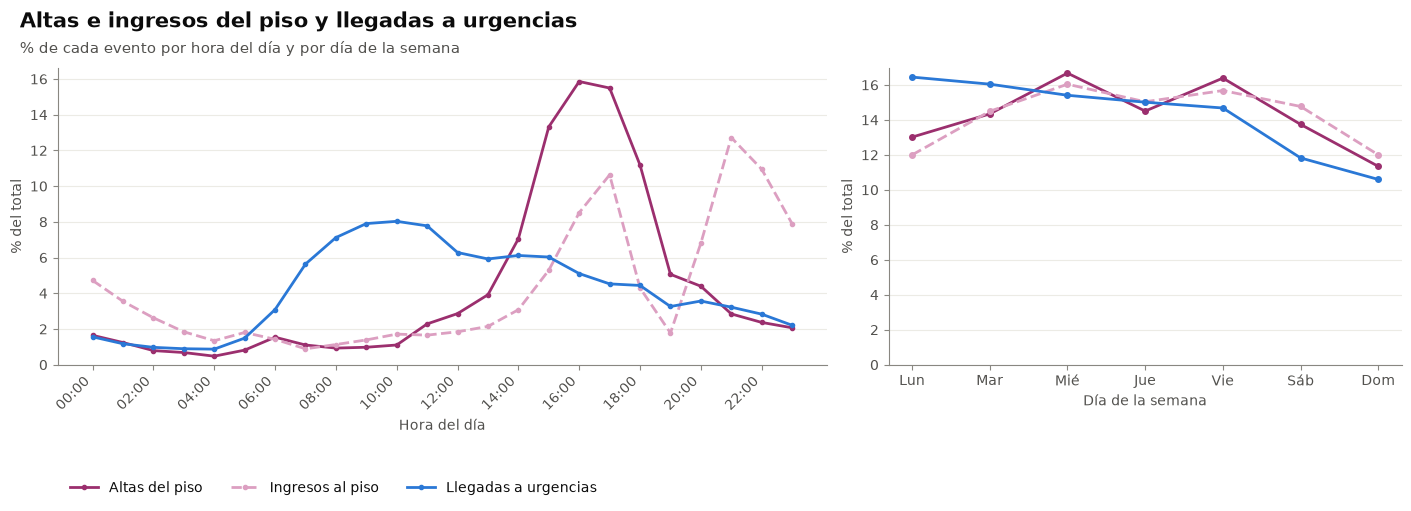

In [21]:
SERIES_FLUJO = {
    'pct_altas_piso': ('Altas del piso', estilo.CIRUELA, '-'),
    'pct_ingresos_piso': ('Ingresos al piso', estilo.RAMPA_CIRUELA[2], '--'),
    'pct_llegadas_urgencias': ('Llegadas a urgencias', estilo.AZUL, '-'),
}
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 2]})
for columna, (etiqueta, color, linea) in SERIES_FLUJO.items():
    ejes[0].plot(altas_por_hora.index, altas_por_hora[columna], marker='o', markersize=3, color=color, linestyle=linea,
                 label=etiqueta)
    ejes[1].plot(range(7), altas_por_dia[columna], marker='o', markersize=4, color=color, linestyle=linea, label=etiqueta)
ejes[0].set_xticks(range(0, 24, 2), [f'{h:02d}:00' for h in range(0, 24, 2)], rotation=45, ha='right')
ejes[0].set_xlabel('Hora del día')
ejes[1].set_xticks(range(7), estilo.DIAS_SEMANA)
ejes[1].set_xlabel('Día de la semana')
for ax in ejes:
    ax.set_ylabel('% del total')
    ax.set_ylim(bottom=0)
leyenda_fuera(ejes[0], 'debajo', bbox_to_anchor=(0, -0.35))
titulo_hallazgo(fig, 'Altas e ingresos del piso y llegadas a urgencias',
                '% de cada evento por hora del día y por día de la semana')
guardar_figura(fig, '06_altas_por_hora')
plt.show()

In [22]:
altas = piso.loc[~excluir_alta, 'fin']
conteo_tramo = pd.crosstab(oc.tramo_horario(altas).to_numpy(), altas.dt.dayofweek.to_numpy())
conteo_tramo = conteo_tramo.reindex(columns=range(7), fill_value=0)
pct_tramo = (100 * conteo_tramo / conteo_tramo.sum()).where(conteo_tramo >= config.MIN_CELDA)
pct_tramo.columns = estilo.DIAS_SEMANA_COMPLETOS
pct_tramo.index.name = 'tramo'
mostrar_tabla(pct_tramo.round(1), '% de altas del piso de cada día por tramo horario (celdas con menos de 10 altas ocultas)')

**% de altas del piso de cada día por tramo horario (celdas con menos de 10 altas ocultas)**

,lunes,martes,miércoles,jueves,viernes,sábado,domingo
tramo,,,,,,,
00–06,"3,70",6,"5,40","6,80",5,"6,70",6
06–12,"7,70","7,80","7,90","7,70","7,60","7,90","9,30"
12–18,"59,50","56,50","58,20","55,90","60,60","56,60","62,80"
18–24,29,"29,80","28,50","29,60","26,80","28,70","21,80"


## 8. Etapas de urgencias después del inicio del piso

Horas-paciente de hospitalizados con fin de urgencias posterior al inicio del piso que quedan después del inicio del piso y, por eso, fuera del censo de urgencias.

In [23]:
hosp_despues = episodios[episodios['en_poblacion'] & episodios['valido_para_tiempos'].astype(bool)
                         & episodios['grupo'].eq(G3) & episodios['fin_urg'].gt(episodios['inicio_piso'])]
censo_despues = oc.censo_horario(hosp_despues['inicio_piso'], hosp_despues['fin_urg'], INICIO_CENSO, HASTA)
horas_censo = censos['urgencias_atencion']['total'].sum()
etapas_despues = pd.DataFrame({
    'n_episodios': [len(hosp_despues)],
    'horas_paciente_despues_inicio_piso': [censo_despues.sum()],
    'horas_paciente_censo_urgencias_atencion': [horas_censo],
    'pct_horas_paciente_censo': [100 * censo_despues.sum() / horas_censo],
    'maximo_simultaneo': [censo_despues.max()],
}, index=pd.Index(['Hospitalizados'], name='grupo'))
mostrar_tabla(tabla_segura(etapas_despues, decimales=2, columnas_derivadas=[]), 'Horas-paciente de urgencias después del inicio del piso')

**Horas-paciente de urgencias después del inicio del piso**

,n_episodios,horas_paciente_despues_inicio_piso,horas_paciente_censo_urgencias_atencion,pct_horas_paciente_censo,maximo_simultaneo
grupo,,,,,
Hospitalizados,1.329,108352,3813895,"2,8",16


## Exportación

Tablas agregadas en `data/processed/`; los conteos de episodios menores a 10 se suprimen.

In [24]:
filas = []
for area, censo_area in censos.items():
    for grupo in GRUPOS_CENSO:
        diario = oc.resumen_diario(censo_area[grupo])
        for posicion, (etiqueta, camas) in enumerate(CAPACIDAD[area][grupo].items()):
            sufijo = '' if posicion == 0 else f'_{etiqueta}'
            diario[f'pct_promedio_capacidad_actual_2026{sufijo}'] = (100 * diario['promedio'] / camas if USAR_CAPACIDAD[area]
                                                                    else np.nan)
        diario['dia_saturado'] = oc.dias_saturados(oc.horas_saturadas(censo_area[grupo])).reindex(diario.index)
        camas = next(iter(CAPACIDAD[area][grupo].values()))
        diario['dia_saturado_capacidad_actual_2026'] = (
            oc.dias_saturados(censo_area[grupo].gt(0.9 * camas)).reindex(diario.index).astype(object)
            if USAR_CAPACIDAD[area] else np.nan)
        filas.append(diario.reset_index().assign(area=area, grupo_edad=grupo))
ocupacion_diaria = pd.concat(filas, ignore_index=True)
columnas_inicio = ['fecha', 'area', 'grupo_edad', 'promedio', 'p90', 'maximo']
ocupacion_diaria = ocupacion_diaria[columnas_inicio + [c for c in ocupacion_diaria if c not in columnas_inicio]]
columnas_numericas = ocupacion_diaria.select_dtypes('number').columns
ocupacion_diaria[columnas_numericas] = ocupacion_diaria[columnas_numericas].round(2)

ocupacion_hora_dia = pd.concat(
    [oc.matriz_hora_dia(censo_area['total']).stack().rename('censo_promedio').reset_index().assign(area=area)
     for area, censo_area in censos.items()], ignore_index=True)[['area', 'hora', 'dia_semana', 'censo_promedio']]

piso_vs_los = suprimir_pequenos(
    por_decil.round(2), ['n', f'n_mas_{umbral}h'],
    columnas_derivadas=['mediana_h', f'pct_mas_{umbral}h', f'ic_inf_mas_{umbral}h', f'ic_sup_mas_{umbral}h', 'censo_piso_mediano'])
altas_csv = altas_por_hora.round(2).reset_index()

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
exportes = {
    'ocupacion_diaria.csv': ocupacion_diaria,
    'ocupacion_hora_dia.csv': ocupacion_hora_dia.round(2),
    'piso_vs_los.csv': piso_vs_los,
    'altas_por_hora.csv': altas_csv,
}
for nombre, tabla in exportes.items():
    tabla.to_csv(config.DATA_PROCESSED / nombre, index=False)
mostrar_tabla(pd.DataFrame({'filas': {n: len(t) for n, t in exportes.items()},
                            'columnas': {n: t.shape[1] for n, t in exportes.items()}}).rename_axis('archivo'),
              'Archivos exportados en data/processed/')

**Archivos exportados en data/processed/**

,filas,columnas
archivo,,
ocupacion_diaria.csv,10.395,10
ocupacion_hora_dia.csv,504,4
piso_vs_los.csv,120,11
altas_por_hora.csv,24,4
